In [1]:
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
def prob(T, delta_R):
    a=  np.exp(delta_R / T)
    # keep a between 0 and 1 where a is an array
    a = a / (1 + a)
    return a

In [50]:
T_range = np.linspace(1, 0.01, 100)
delta_R_space = [ 0.1, 0.005, 0.001,0.0005, 0.0001, 0.00001, 0.000001]

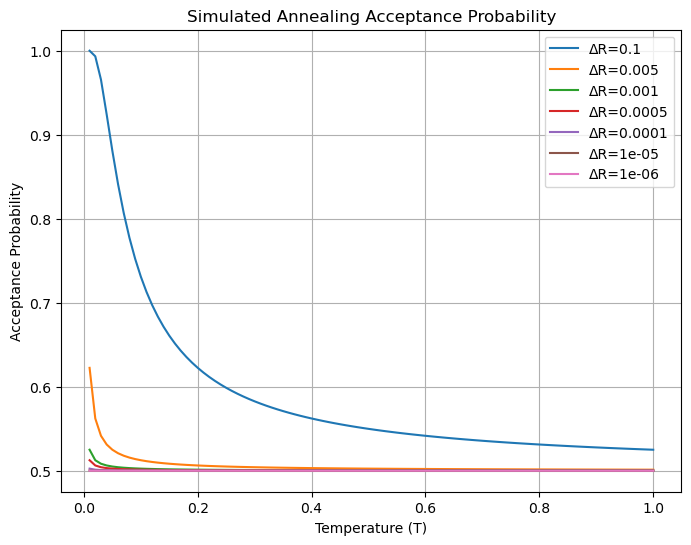

In [51]:
# Plots
plt.figure(figsize=(8,6))
for delta_R in delta_R_space:
    p_vals = prob(T_range, delta_R)
    plt.plot(T_range, p_vals, label=f"ΔR={delta_R}")
plt.xlabel("Temperature (T)")
plt.ylabel("Acceptance Probability")
plt.title("Simulated Annealing Acceptance Probability")
plt.legend()
plt.grid()
plt.show()

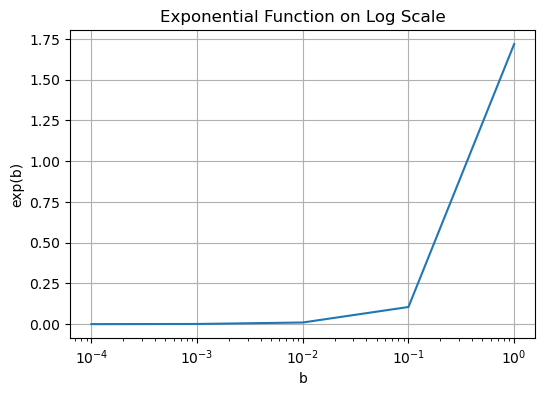

In [60]:
b = [0.0001,0.001,0.01,0.1,1]
a = np.exp(b) -1

# plot
plt.figure(figsize=(6,4))
plt.plot(b, a)
plt.xscale("log")
plt.xlabel("b")
plt.ylabel("exp(b)")
plt.title("Exponential Function on Log Scale")
plt.grid()
plt.show()

In [61]:
# Cell 1 — imports
import numpy as np
import matplotlib.pyplot as plt


In [62]:
# Cell 2 — acceptance probability function (Simulated Annealing)
# Convention: we MINIMIZE "energy" E. If you MAXIMIZE reward R, use E = -R.
# ΔE = E_new - E_old.
# Accept always if ΔE <= 0 (improves energy). Else accept with exp(-ΔE/T).

def accept_prob_deltaE(deltaE, T, eps=1e-12):
    deltaE = np.asarray(deltaE, dtype=np.float64)
    T = np.asarray(T, dtype=np.float64)
    return np.where(deltaE <= 0, 1.0, np.exp(-deltaE / (T + eps)))

# If you prefer to work in reward deltas directly:
# ΔR = R_new - R_old, accept always if ΔR >= 0 else exp(ΔR/T)
def accept_prob_deltaR(deltaR, T, eps=1e-12):
    deltaR = np.asarray(deltaR, dtype=np.float64)
    T = np.asarray(T, dtype=np.float64)
    return np.where(deltaR >= 0, 1.0, np.exp(deltaR / (T + eps)))


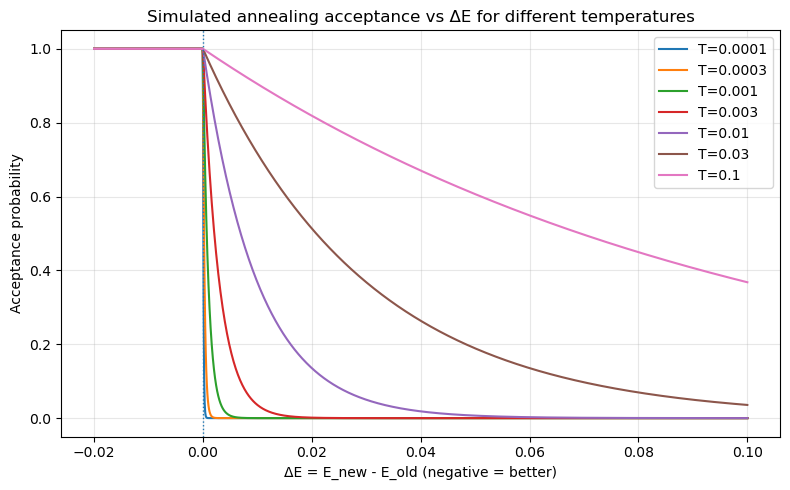

In [63]:
# Cell 3 — plot P_accept vs ΔE for multiple temperatures
# (This is the cleanest “how T changes acceptance” plot.)

Ts = np.array([1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1], dtype=np.float64)
dE = np.linspace(-0.02, 0.10, 1200)  # adjust range to your typical ΔE scale

plt.figure(figsize=(8, 5))
for T in Ts:
    p = accept_prob_deltaE(dE, T)
    plt.plot(dE, p, label=f"T={T:g}")

plt.axvline(0.0, linestyle=":", linewidth=1)
plt.xlabel("ΔE = E_new - E_old (negative = better)")
plt.ylabel("Acceptance probability")
plt.title("Simulated annealing acceptance vs ΔE for different temperatures")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


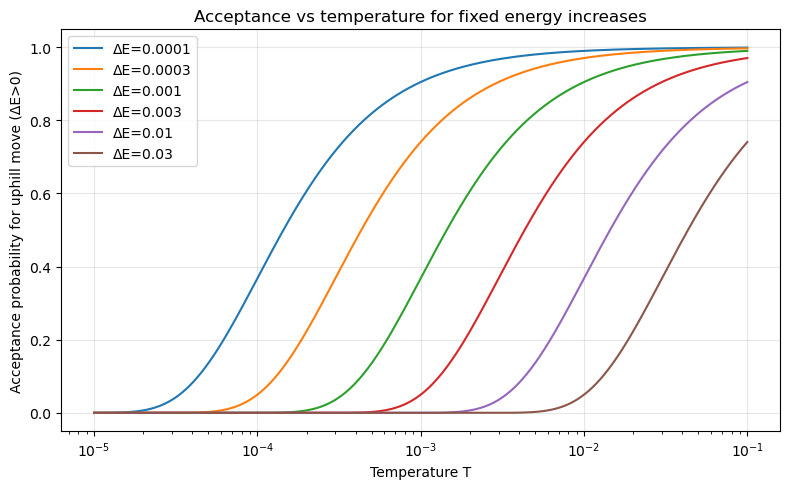

In [65]:
# Cell 4 — plot P_accept vs T for fixed ΔE values
# (Good for explaining “as temperature cools, uphill moves stop happening”.)

dE_vals = np.array([1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2], dtype=np.float64)
T_grid = np.logspace(-5, -1, 600)

plt.figure(figsize=(8, 5))
for dE0 in dE_vals:
    p = accept_prob_deltaE(dE0, T_grid)
    plt.plot(T_grid, p, label=f"ΔE={dE0:g}")

plt.xscale("log")
plt.xlabel("Temperature T")
plt.ylabel("Acceptance probability for uphill move (ΔE>0)")
plt.title("Acceptance vs temperature for fixed energy increases")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


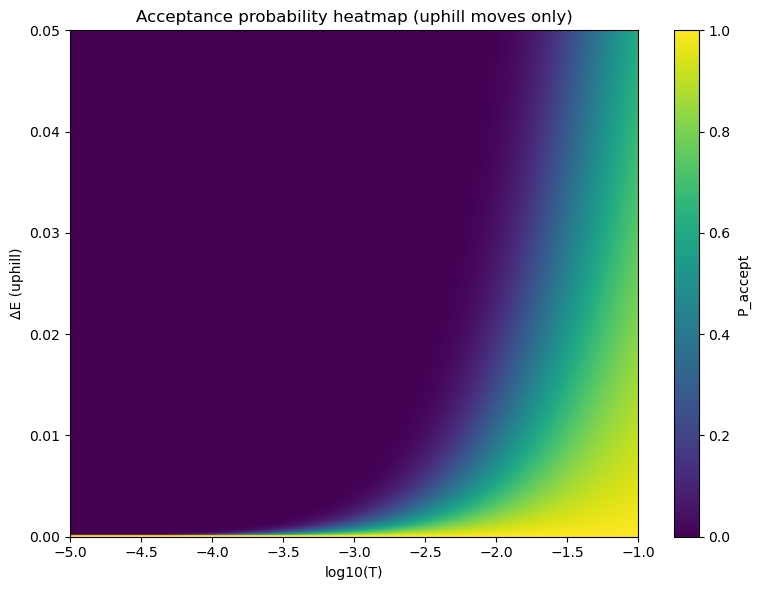

In [66]:
# Cell 5 — 2D heatmap: P_accept across (T, ΔE)
# (Great slide figure: shows the full landscape.)

T_vals = np.logspace(-5, -1, 250)
dE_vals = np.linspace(0.0, 0.05, 250)  # uphill only, where P<1
TT, EE = np.meshgrid(T_vals, dE_vals, indexing="xy")
P = accept_prob_deltaE(EE, TT)

plt.figure(figsize=(8, 6))
im = plt.imshow(
    P,
    aspect="auto",
    origin="lower",
    extent=[np.log10(T_vals.min()), np.log10(T_vals.max()), dE_vals.min(), dE_vals.max()],
)
plt.xlabel("log10(T)")
plt.ylabel("ΔE (uphill)")
plt.title("Acceptance probability heatmap (uphill moves only)")
plt.colorbar(im, label="P_accept")
plt.tight_layout()
plt.show()


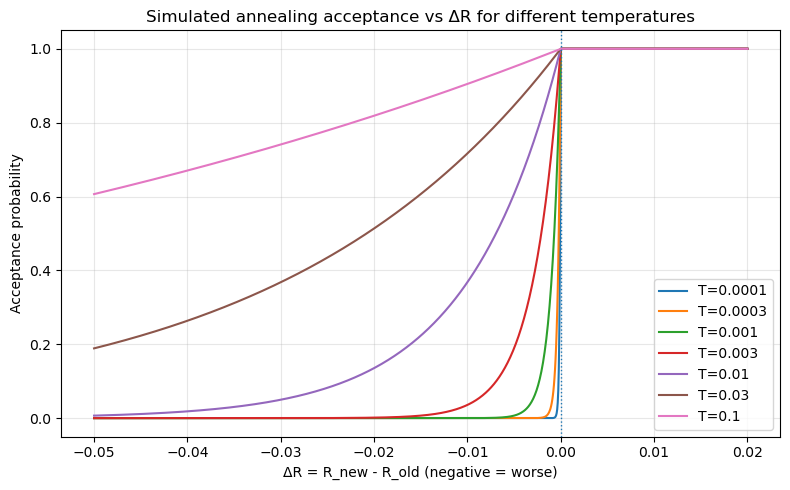

In [67]:
# Cell 6 — same plots but in terms of reward deltas ΔR (if you maximize trace)
# Here uphill in energy corresponds to negative ΔR.
# Choose a ΔR range that matches what you see in logs.

Ts = np.array([1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1], dtype=np.float64)
dR = np.linspace(-0.05, 0.02, 1200)  # negative = worse reward

plt.figure(figsize=(8, 5))
for T in Ts:
    p = accept_prob_deltaR(dR, T)
    plt.plot(dR, p, label=f"T={T:g}")

plt.axvline(0.0, linestyle=":", linewidth=1)
plt.xlabel("ΔR = R_new - R_old (negative = worse)")
plt.ylabel("Acceptance probability")
plt.title("Simulated annealing acceptance vs ΔR for different temperatures")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


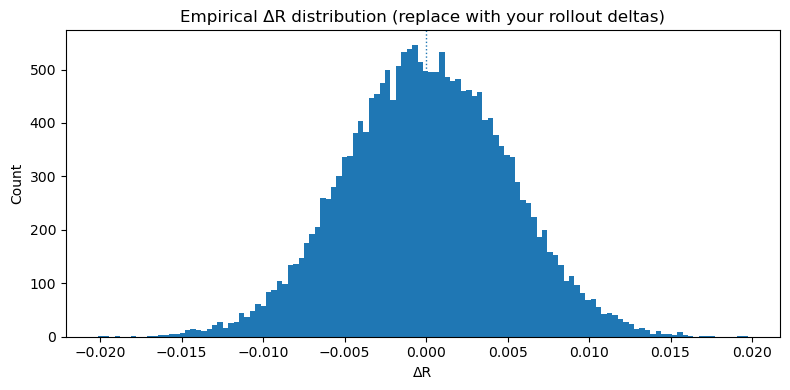

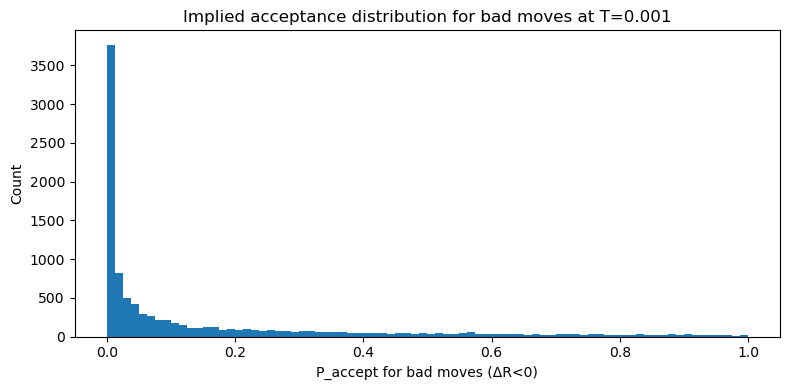

Mean P_accept (bad moves) at T=0.001: 0.1543
Fraction bad moves accepted at T=0.001 (expected): 0.1543


In [68]:
# Cell 7 — OPTIONAL: overlay your empirical ΔE (or ΔR) histogram and show implied P_accept
# Paste your logged deltas into `deltas` (e.g., from a rollout).

# Example synthetic deltas; replace with your real data:
rng = np.random.default_rng(0)
deltas = rng.normal(loc=0.0, scale=0.005, size=20000)  # could be ΔR
# If this is ΔR, acceptance is accept_prob_deltaR(deltas, T). If ΔE, use accept_prob_deltaE.

T = 1e-3

p = accept_prob_deltaR(deltas, T)
p_uphill = p[deltas < 0]  # "bad" moves (ΔR<0)

plt.figure(figsize=(8, 4))
plt.hist(deltas, bins=120)
plt.axvline(0.0, linestyle=":", linewidth=1)
plt.xlabel("ΔR")
plt.ylabel("Count")
plt.title("Empirical ΔR distribution (replace with your rollout deltas)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(p_uphill, bins=80)
plt.xlabel("P_accept for bad moves (ΔR<0)")
plt.ylabel("Count")
plt.title(f"Implied acceptance distribution for bad moves at T={T:g}")
plt.tight_layout()
plt.show()

print(f"Mean P_accept (bad moves) at T={T:g}: {p_uphill.mean():.4f}")
print(f"Fraction bad moves accepted at T={T:g} (expected): {p_uphill.mean():.4f}")
